In [1]:
# %matplotlib widget
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.collections import LineCollection
from scipy.ndimage import gaussian_filter1d
from pathlib import Path

In [70]:
light_on_frame = np.array([89, 39, 90, 64, 32, 32, 73, 58, 53, 42, 80, 55, 44, 71, 44, 38, 38, 41, 29, 88, 55, 44, 43, 45, 45, 34, 46, 47, 55, 38, 94, 53, 37])

In [9]:
# data available
file_names = [
    "Clip0001_1C_4N_G_1",
    "Clip0003_1C_4N_G_3",
    "Clip0006_1C_4N_G_6",
    "Clip0009_1C_4N_G_8",
    "Clip0010_1C_4N_G_9",
    "Clip0011_1C_4N_G_10",
    "Clip0017_1C_4N_T_6",
    "Clip0020_1C_4N_T_8",
    "Clip0021_1C_4N_T_9",
    "Clip0022_1C_4N_T_10",
    "Clip0023_1C_4N_E2_1",
    "Clip0042_1C_4N_E4_10",
    "Clip0049_1C_4N_E9_7",
    "Clip0050_1C_4N_E9_8",
    "Clip0058_1C_4N_E7_6",
    "Clip0070_1C_4N_E3_8",
    "Clip0074_1C_4N_E8_1",
    "Clip0078_1C_4N_E8_5",
    "Clip0079_1C_4N_E8_6",
    "Clip0079_E7_1",
    "Clip0080_1C_4N_E8_7",
    "Clip0081_1C_4N_E8_8",
    "Clip0081_E7_3",
    "Clip0082_1C_4N_E8_9",
    "Clip0082_E7_4",
    "Clip0083_E7_5",
    "Clip0084_E7_6",
    "Clip0085_E7_7",
    "Clip0088_E7_10",
    "Clip0092_E2_4",
    "Clip0094_E2_6",
    "Clip0095_E2_7",
    "Clip0107_E3_9"
]

reaction_windows = np.array([
    [110, 126, 2],
    [71, 103, 2],
    [122, 155, 0],
    [80, 104, 4],
    [38, 61, 1],
    [58, 128, 2],
    [91, 111, 2],
    [74, 103, 0],
    [54, 70, 4],
    [44, 73, 0],
    [95, 126, 3],
    [58, 102, 3],
    [55, 83, 0],
    [86, 131, 3],
    [90, 145, 0],
    [44, 75, 3],
    [55, 85, 0],
    [49, 70, 3],
    [59, 85, 4],
    [110, 152, 0],
    [62, 93, 3],
    [50, 118, 2],
    [61, 97, 4],
    [44, 92, 1],
    [46, 89, 0],
    [44, 92, 2],
    [58, 74, 0],
    [60, 102, 1],
    [63, 88, 2],
    [66, 89, 0],
    [52, 80, 1],
    [71, 99, 1],
    [43, 62, 0]
])  

parent_dir = Path('/home/hck03/Documents/MS_thesis/tracking_output/1c_4n_faulty')

In [10]:
print(file_names[-5])

Clip0088_E7_10


In [11]:
def plot_window(window, speed, omega):
    plt.close()
    # id = 3
    x = np.arange(window[0], window[1]+1)
    y1 = omega
    y2 = speed

    fig, ax1 = plt.subplots(figsize=(8, 5))
    color1 = 'blue'
    ax1.set_xlabel('Time (s)')
    ax1.set_ylabel('Angular Velocity (deg/s)')
    ax1.plot(x, y1, color=color1, linewidth=2, label='Velocity')
    ax1.tick_params(axis='y')
    # ax1.set_xlim(58, 102)
    ax1.set_ylim(bottom=0)
    # ax1.set_ylim(-10, 2000)

    ax2 = ax1.twinx()

    color2 = 'orange'
    ax2.set_ylabel('speed cm/s')
    ax2.plot(x, y2, color=color2, linewidth=2, label='speed')
    ax2.tick_params(axis='y')
    # ax2.set_ylim(-10, 50)
    ax2.set_ylim(bottom=0)
    plt.axhline(y=0.0, color='k', linestyle='--', alpha=0.5)
    fig.tight_layout()
    plt.show()

    
def kinematic_signature(window, dt=0.01):
    # distance-time variables
    vel = np.gradient(window, axis=0)/dt
    speed = np.linalg.norm(vel, axis=1)
    speed_smooth = gaussian_filter1d(speed, sigma=3)
    # acc_mag = np.gradient(speed_smooth, axis=1)

    theta = np.arctan2(vel[..., 1], vel[..., 0])
    theta_unwrapped = np.unwrap(theta)

    dtheta = np.degrees(theta_unwrapped)
    omega = np.gradient(dtheta, axis=0) / dt

    # alpha = np.gradient(omega, axis=1)    

    # alpha_smooth = gaussian_filter1d(alpha, sigma=3)
    omega_smooth = np.abs(gaussian_filter1d(omega, sigma=3))

    return speed_smooth, omega_smooth


/home/hck03/Documents/MS_thesis/tracking_output/1c_4n_faulty/Clip0107_E3_9/data/clean_tracks.npy


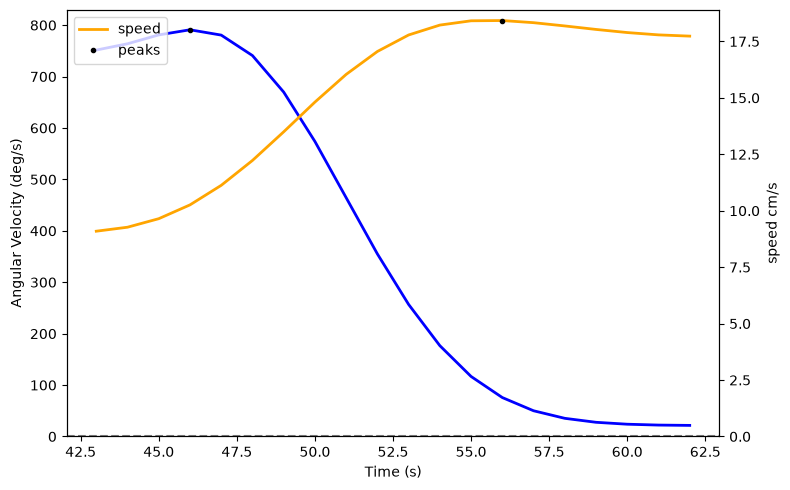

In [12]:
from scipy.signal import find_peaks

id_of_interest = 32
file_name_i = parent_dir / file_names[id_of_interest] / "data" / 'clean_tracks.npy'
print(file_name_i)
reaction_window = reaction_windows[id_of_interest, :]
c_fish_idx = reaction_window[-1]
start = reaction_window[0]
end = reaction_window[1]
data = np.load(file_name_i)
data_i = np.squeeze(data[c_fish_idx, start:end+1,:])

speed, omega = kinematic_signature(data_i)

# finding peaks
omega_peaks, omega_properties = find_peaks(omega, prominence=100)
if len(omega_peaks) == 0:
    max_omega = np.max(omega)
    max_omega_idx = np.argmax(omega)
else:
    best_peak_idx = np.argmax(omega_properties['prominences'])
    max_omega_idx = omega_peaks[best_peak_idx]
    max_omega = omega[max_omega_idx]  

speed_peaks, speed_properties = find_peaks(speed, prominence=4)
if len(speed_peaks) == 0:
    max_speed = np.max(speed)
    max_speed_idx = np.argmax(speed)
else:
    best_peak_idx = np.argmax(speed_properties['prominences'])
    max_speed_idx = speed_peaks[best_peak_idx]
    max_speed = speed[max_speed_idx]  

x = np.arange(start, end+1)
y1 = omega
y2 = speed

fig, ax1 = plt.subplots(figsize=(8, 5))
color1 = 'blue'
ax1.set_xlabel('Time (s)')
ax1.set_ylabel('Angular Velocity (deg/s)')
ax1.plot(x, y1, color=color1, linewidth=2, label='angular velocity')
ax1.tick_params(axis='y')
ax1.plot(x[max_omega_idx], omega[max_omega_idx], "o", color='k', markersize=3, label='peaks')
ax1.set_ylim(bottom=0)
# ax1.set_ylim(0, 200)

ax2 = ax1.twinx()

color2 = 'orange'
ax2.set_ylabel('speed cm/s')
ax2.plot(x, y2, color=color2, linewidth=2, label='speed')
ax2.tick_params(axis='y')
# ax2.set_ylim(-10, 50)
ax2.set_ylim(bottom=0)
ax2.plot(x[max_speed_idx], speed[max_speed_idx], "o", color='k', markersize=3, label='peaks')
plt.axhline(y=0.0, color='k', linestyle='--', alpha=0.5)
fig.tight_layout()
plt.legend()
plt.show()



In [14]:
def peak_finder(omega, speed):
    omega_peaks, omega_properties = find_peaks(omega, prominence=100)
    if len(omega_peaks) == 0:
        max_omega = np.max(omega)
        max_omega_idx = np.argmax(omega)
    else:
        best_peak_idx = np.argmax(omega_properties['prominences'])
        max_omega_idx = omega_peaks[best_peak_idx]
        max_omega = omega[max_omega_idx]  

    speed_peaks, speed_properties = find_peaks(speed, prominence=4)
    if len(speed_peaks) == 0:
        max_speed = np.max(speed)
        max_speed_idx = np.argmax(speed)
    else:
        best_peak_idx = np.argmax(speed_properties['prominences'])
        max_speed_idx = speed_peaks[best_peak_idx]
        max_speed = speed[max_speed_idx]  

    return max_omega, max_omega_idx, max_speed, max_speed_idx


In [17]:
speed_max_array_C = []
omega_max_array_C = []
speed_max_array_N = []
omega_max_array_N = []
for i, f in enumerate(file_names):
    file_name = parent_dir / f / "data" / 'clean_tracks.npy'
    # print(file_name)
    reaction_window = reaction_windows[i, :]
    c_fish_idx = reaction_window[-1]
    n_fish_idx = np.delete(np.arange(5), c_fish_idx)
    start = reaction_window[0]
    end = reaction_window[1]
    data = np.load(file_name)
    data_r = np.squeeze(data[c_fish_idx, start:end+1,:])

    speed, omega = kinematic_signature(data_r)

    # finding peaks
    m_o, m_o_i, m_s, m_s_i = peak_finder(omega, speed)

    speed_max_array_C.append((m_s, m_s_i + start))
    omega_max_array_C.append((m_o, m_o_i + start))

    n_fish_omega_i_list = []
    n_fish_speed_i_list = []
    for n_fish in n_fish_idx:
        data_n = np.squeeze(data[n_fish, start:end+1,:])
        speed_n, omega_n = kinematic_signature(data_n)
        m_o_n, m_o_i_n, m_s_n, m_s_i_n = peak_finder(omega_n, speed_n)
        n_fish_omega_i_list.append((m_o_n, m_o_i_n + start))
        n_fish_speed_i_list.append((m_s_n, m_s_i_n + start))
    speed_max_array_N.append(n_fish_speed_i_list)
    omega_max_array_N.append(n_fish_omega_i_list)

In [86]:
reaction_latency_c = np.array(omega_max_array_C)[:,1] - light_on_frame
reaction_latency_n = np.ravel(np.array(omega_max_array_N)[:,:,1] - light_on_frame[:, np.newaxis])
latency_all = np.concatenate((reaction_latency_c, reaction_latency_n))

In [75]:
np.array(omega_max_array_N).shape

(33, 4, 2)

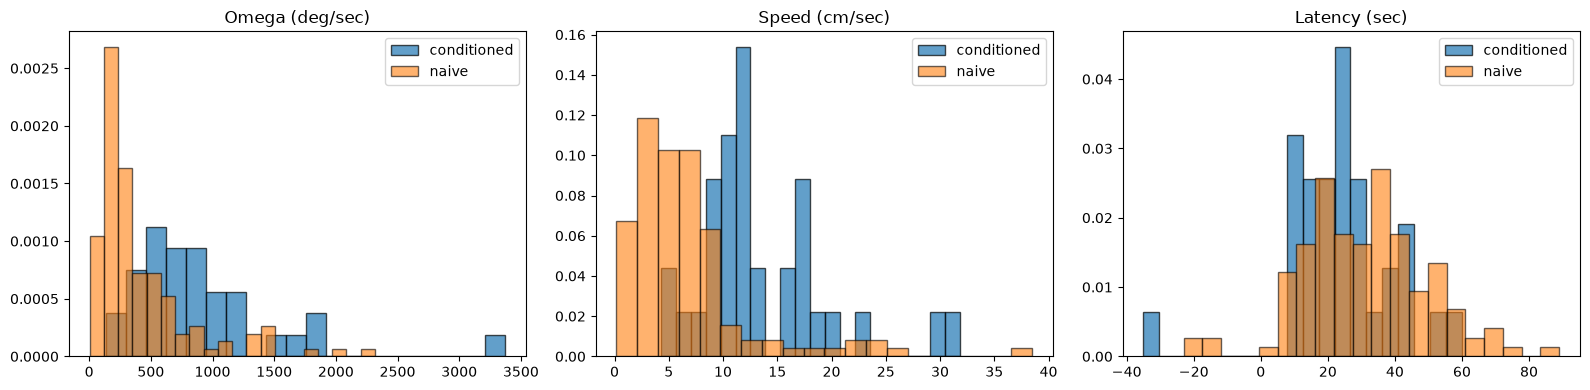

In [103]:
# plotting distribution of av_max
# conditioned
omega_max_val_c = np.array(omega_max_array_C)[:,0]
speed_max_val_c = np.array(speed_max_array_C)[:,0]
c_lables = np.ones(len(speed_max_val_c))
# naive
omega_max_val_n = np.ravel(np.array(omega_max_array_N)[:,:, 0])
speed_max_val_n = np.ravel(np.array(speed_max_array_N)[:,:,0])
n_lables = np.zeros(len(speed_max_val_n))

plt.close()
fig, ax = plt.subplots(1,3, figsize=(16,4))
ax[0].hist(omega_max_val_c, bins=20,density=True, edgecolor='black', alpha=0.7, label='conditioned')
ax[0].hist(omega_max_val_n, bins=20, density=True, alpha=0.6, edgecolor='k', label='naive')
ax[0].set_title('Omega (deg/sec)')
ax[0].legend()

ax[1].hist(speed_max_val_c, bins=20,density=True, edgecolor='black', alpha=0.7, label='conditioned')
ax[1].hist(speed_max_val_n, bins=20, density=True, alpha=0.6, edgecolor='k', label='naive')
ax[1].set_title('Speed (cm/sec)')
ax[1].legend()

ax[2].hist(reaction_latency_c, bins=20,density=True, edgecolor='black', alpha=0.7, label='conditioned')
ax[2].hist(reaction_latency_n, bins=20, density=True, alpha=0.6, edgecolor='k', label='naive')
ax[2].set_title('Latency (sec)')
ax[2].legend()
plt.tight_layout()
plt.show()
# plt.legend()


In [98]:
# lets plot a scatter plot for speed vs omega and see how this works
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_recall_curve

speed_all = np.concatenate((speed_max_val_c, speed_max_val_n))
omega_all = np.concatenate((omega_max_val_c, omega_max_val_n))

X = np.column_stack((speed_all, omega_all, latency_all))
labels = np.concatenate((c_lables, n_lables))

model = LogisticRegression(class_weight='balanced')
model.fit(X, labels)


,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the fol

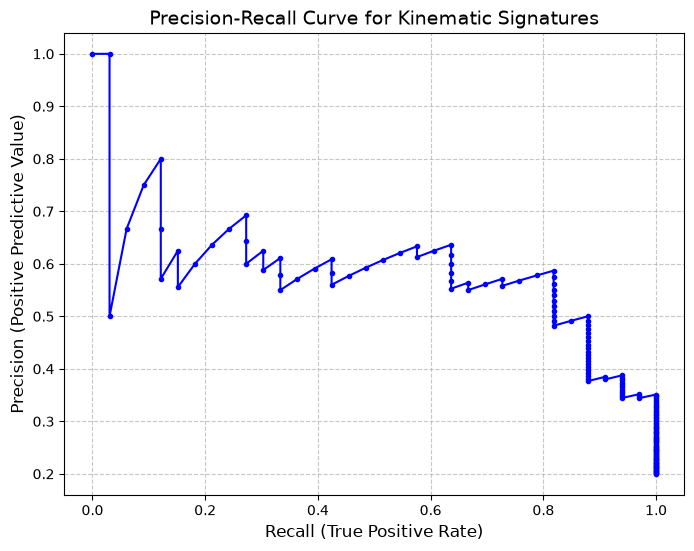

In [99]:
y_scores = model.predict_proba(X)[:, 1]

precision, recall, thresholds = precision_recall_curve(labels, y_scores)

f1_scores = 2 * (precision[:-1] * recall[:-1]) / (precision[:-1] + recall[:-1] + 1e-10)
optimal_idx = np.argmax(f1_scores)
optimal_p = thresholds[optimal_idx]

plt.figure(figsize=(8, 6))
plt.plot(recall, precision, marker='.', color='b', label='Logistic Regression')
plt.xlabel('Recall (True Positive Rate)', fontsize=12)
plt.ylabel('Precision (Positive Predictive Value)', fontsize=12)
plt.title('Precision-Recall Curve for Kinematic Signatures', fontsize=14)
plt.grid(True, linestyle='--', alpha=0.7)

In [100]:
optimal_p

np.float64(0.5452171404496692)

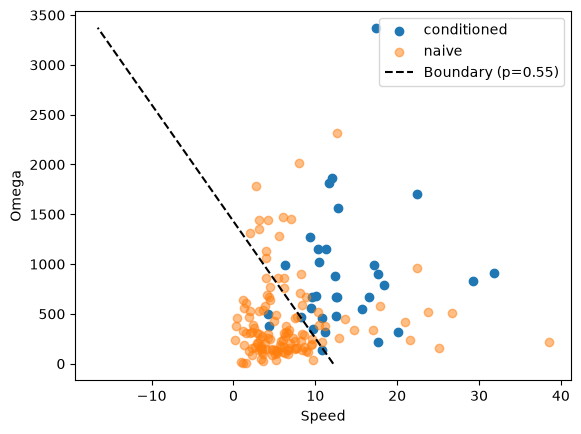

In [101]:
beta_0 = model.intercept_[0]         
beta_1 = model.coef_[0][0]           
beta_2 = model.coef_[0][1]

omega_line = np.linspace(0, np.max(omega_all), 100)

target_probability = optimal_p
z_score = np.log(target_probability / (1 - target_probability))

# CORRECTED MATH: Subtract (beta_2 * omega) and divide by beta_1
speed_line = (z_score - beta_0 - (beta_2 * omega_line)) / beta_1

# Plotting
plt.scatter(speed_max_val_c, omega_max_val_c, label='conditioned')
plt.scatter(speed_max_val_n, omega_max_val_n, alpha=0.5, label='naive')
plt.plot(speed_line, omega_line, color='k', linestyle='--', label=f'Boundary (p={optimal_p:.2f})')
plt.legend()
plt.xlabel("Speed")
plt.ylabel("Omega")
plt.show()

In [ ]:
# leave one out cross validation 